In [1]:
!pip install opendatasets neurokit2 --upgrade --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 20.7 MB/s eta 0:00:00


In [2]:
import os
import pandas as pd
import numpy as np
import neurokit2 as nk
from numba import njit
import scipy.signal
import json
import opendatasets as od

In [3]:
download_url = "https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023/data"
od.download(download_url)

Dataset URL: https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023


In [4]:
def load_mlII_signals(data_dir):
    all_vectors = []
    patient_files = sorted([f for f in os.listdir(data_dir) if f.endswith(".csv")])

    for file in patient_files:
        filepath = os.path.join(data_dir, file)
        df = pd.read_csv(filepath)

        if 'MLII' in df.columns:
            mlII_signal = df['MLII'].values

            if len(mlII_signal) >= 650000:
                mlII_signal = mlII_signal[:650000]
            else:
                mlII_signal = np.pad(mlII_signal, (0, 650000 - len(mlII_signal)), 'constant')
            all_vectors.append(mlII_signal)
        else:
            print(f"MLII not found in {file}, skipping.")


    return np.stack(all_vectors, axis=1)


In [5]:
data_path = '/content/mit-bih-arrhythmia-database-modern-2023'
mlII_matrix = load_mlII_signals(data_path)
print("Data shape:", mlII_matrix.shape)

MLII not found in 102.csv, skipping.
MLII not found in 104.csv, skipping.
Data shape: (650000, 46)


In [6]:
np.random.seed(42)

def jitter(signal, sigma=0.05):

    return signal + np.random.normal(0, sigma, size=signal.shape)

def scaling(signal, factor_range=(0.9, 1.1)):

    factor = np.random.uniform(*factor_range)
    return signal * factor

def time_warp(signal, warp_amount=2000):

    warped = scipy.signal.resample(signal, len(signal) + warp_amount)
    return warped[:len(signal)]

def generate_augmented_signals(signal, num_augments=2):
    augmented = [signal]
    for _ in range(num_augments):
        aug = jitter(signal)
        aug = scaling(aug)
        aug = time_warp(aug)
        augmented.append(aug)
    return augmented

def expand_dataset(ecg_matrix, num_augments_per_signal=2):
    original_len, num_signals = ecg_matrix.shape
    all_signals = []

    for i in range(num_signals):
        signal = ecg_matrix[:, i]
        augmented_versions = generate_augmented_signals(signal, num_augments=num_augments_per_signal)
        all_signals.extend(augmented_versions)

    return np.stack(all_signals, axis=1)

In [7]:
augmented_matrix = expand_dataset(mlII_matrix, num_augments_per_signal=1)

print("Original shape:", mlII_matrix.shape)
print("Augmented shape:", augmented_matrix.shape)

Original shape: (650000, 46)
Augmented shape: (650000, 92)


In [8]:
fs = 360

@njit
def refine_r_peaks(signal, r_peaks, window=100):
    refined_peaks = []
    for idx in r_peaks:
        start = max(0, idx - window)
        end = min(len(signal), idx + window)
        segment = signal[start:end]
        pos_idx = segment.argmax()
        local_peak = pos_idx + start
        refined_peaks.append(local_peak)
    return np.array(refined_peaks)

all_refined_r_peaks = []

for i in range(augmented_matrix.shape[1]):
    signal = augmented_matrix[:, i]

    try:

        signal = signal - np.mean(signal)
        signal = signal / np.std(signal)


        _, info = nk.ecg_peaks(signal, sampling_rate=fs)
        r_peaks = info["ECG_R_Peaks"]


        refined_peaks = refine_r_peaks(signal, r_peaks)
        all_refined_r_peaks.append(refined_peaks)

    except Exception as e:
        print(f" Skipped patient {i+1} due to error: {e}")
        all_refined_r_peaks.append([])

print("\n Done! All patients processed.")


 Done! All patients processed.


In [9]:
def create_rpeak_labels_matrix(r_peaks_all, total_length=650000, num_patients=92):
    labels_matrix = np.zeros((total_length, num_patients), dtype=int)

    for i in range(num_patients):
        r_peaks = r_peaks_all[i]
        labels_matrix[r_peaks, i] = 1

    return labels_matrix

In [10]:
def create_rpeak_window_labels(label_matrix, seq_len=50):
    y_all = []

    for patient_idx in range(label_matrix.shape[1]):
        labels = label_matrix[:, patient_idx]

        for start in range(0, len(labels) - seq_len + 1, seq_len):
            window = labels[start:start + seq_len]
            y_all.append(1 if np.sum(window) > 0 else 0)

    return np.array(y_all)

In [11]:
def create_clean_noisy_sequences(data_matrix, seq_len=50, noise_std=0.05):
    X_all, y_all = [], []

    for patient_idx in range(data_matrix.shape[1]):
        signal = data_matrix[:, patient_idx]

        for start in range(0, len(signal) - seq_len + 1, seq_len):
            clean_segment = signal[start:start + seq_len]
            noisy_segment = clean_segment + np.random.normal(0, noise_std, size=seq_len)

            X_all.append(noisy_segment)
            y_all.append(clean_segment)

    X_all = np.array(X_all)[..., np.newaxis]
    y_all = np.array(y_all)[..., np.newaxis]
    return X_all, y_all

In [12]:
def load_patient_split(split_path="patient_split.json"):
    with open(split_path, "r") as f:
        return json.load(f)

def get_data_by_split(ecg_matrix, labels, split):
    return (
        (ecg_matrix[:, split["train"]], [labels[i] for i in split["train"]]),
        (ecg_matrix[:, split["val"]],   [labels[i] for i in split["val"]]),
        (ecg_matrix[:, split["test"]],  [labels[i] for i in split["test"]])
    )


In [13]:
split = load_patient_split("patient_split.json")

(_, _), (_, _), (test_data, test_labels) = get_data_by_split(augmented_matrix, all_refined_r_peaks, split)

rpeak_labels_matrix = create_rpeak_labels_matrix(all_refined_r_peaks)
y_test = create_rpeak_window_labels(rpeak_labels_matrix[:, split["test"]])

from tensorflow.keras.models import load_model
denoise_model = load_model("/content/best_overall_lstm_model.keras")          # LSTM denoiser
gru_model     = load_model("/content/best_overall_gru_model.keras")           # GRU classifier

X_noisy, _ = create_clean_noisy_sequences(test_data)
print("Noisy input shape:", X_noisy.shape)

X_denoised = denoise_model.predict(X_noisy)
print("Denoised shape:", X_denoised.shape)

y_pred_probs = gru_model.predict(X_denoised)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

Noisy input shape: (104000, 50, 1)
3250/3250 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step
Denoised shape: (104000, 50, 1)
3250/3250 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step


In [14]:
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Negative', 'Positive']

# f1 Score
print(" Classification Report:")
print(classification_report(y_test, y_pred, digits=4, target_names=labels))


 Classification Report:
              precision    recall  f1-score   support

    Negative     0.9658    0.9872    0.9764     88056
    Positive     0.9197    0.8070    0.8597     15944

    accuracy                         0.9596    104000
   macro avg     0.9428    0.8971    0.9181    104000
weighted avg     0.9587    0.9596    0.9585    104000



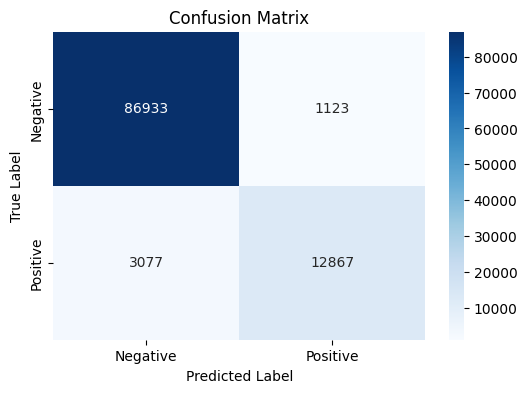

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

df_cm = pd.DataFrame(cm, index=labels, columns=labels)
plt.figure(figsize=(6, 4))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()